# 15-sign GRU with hands, pose and face: 50 epochs

Train a new model from scratch using aligned existing MediaPipe hand, pose and face features. The frozen previous 15-sign GRU remains the comparison. All 478 face XYZ landmarks, 52 blendshape scores and a face-validity mask join the original 254 features for every frame. The same original frame indices are used for all modalities, up to 128 frames. Original official signer-disjoint splits are retained.

This is a first face-feature experiment, not a pure face-only ablation: the input dimension and training randomness change. The validation set informed earlier experiments and the test set was previously examined; neither is a new blind benchmark. Face extraction is complete; this notebook does not re-extract or modify the original caches. Webcam integration is separate.

In [1]:
from pathlib import Path
import sys,json,random,time,hashlib,copy
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset,DataLoader
from torch.nn.utils.rnn import pack_padded_sequence,pad_packed_sequence
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support,confusion_matrix
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/sign_language').is_dir());sys.path.insert(0,str(ROOT/'src'))
from sign_language.expanded_pilot import SIGNS
from sign_language.trajectory_geometry import trajectory_batch,fit_statistics,FEATURES
from sign_language.temporal_augmentation import temporal_clip,CONFIG as TEMPORAL_CONFIG
from sign_language.five_sign_pilot import POLICY,select_epoch,early_stop_reason,sha256
PARENT=ROOT/'data/training/asl-gru-128-v1';FACE=ROOT/'data/landmarks/asl-citizen-face-fifteen-v1'
OLD=ROOT/'models/asl-gru-fifteen-signs-trajectory-readout-c01/best.pt'
OUT=ROOT/'models/asl-gru-fifteen-signs-face-50epochs-v1'
manifest=json.loads((PARENT/'manifest.json').read_text());face_report=json.loads((FACE/'summary.json').read_text())
assert face_report['status']=='complete' and face_report['clips']==461
assert len(face_report['blendshape_names'])==52
labels={s:i for i,s in enumerate(SIGNS)};assert not OUT.exists(),'Choose a new run directory; existing artifacts are never overwritten'
assert torch.cuda.is_available();torch.set_num_threads(2);torch.backends.cudnn.enabled=False;torch.backends.cudnn.benchmark=False
baseline_hash=sha256(OLD);np.random.seed(42);random.seed(42);torch.manual_seed(42);torch.cuda.manual_seed_all(42)
face_records={r['video_file']:r for r in face_report['records']}
print('GPU:',torch.cuda.get_device_name(),'face records',len(face_records),'baseline',baseline_hash)

GPU: NVIDIA GeForce RTX 4060 face records 461 baseline 34b766c393cf20a77b001004376195e60ffb58943d7b1f9661bd23edbab81c91


## Build aligned sequences

For each clip, use the same ordered frame indices that created the original 128-frame hand/pose cache. Face XYZ is adjusted for image aspect ratio, centered on the nose and divided by the clip's median inter-eye distance; depth stays face-local. Invalid/missing faces are zero-filled and masked. Blendshape scores are kept as supplied. This normalization removes absolute face location; coarse head/face location remains in the existing pose channels. This choice is a hypothesis to evaluate, not a proven optimum.

In [2]:
class JoinedFaceDataset(Dataset):
    def __init__(self,split):
        self.split=split
        rows=json.loads((PARENT/f'{split}-index.json').read_text())
        self.ids=[i for i,r in enumerate(rows) if r['gloss'] in labels]
        self.rows=[rows[i] for i in self.ids]
        self.body=np.load(PARENT/f'{split}-features.npy',mmap_mode='r')
        self.lengths=np.load(PARENT/f'{split}-lengths.npy',mmap_mode='r')
        self.targets=np.load(PARENT/f'{split}-targets.npy',mmap_mode='r')
        self.items=[];self.people={r['participant_id'] for r in self.rows};missing=0
        for i,row in zip(self.ids,self.rows,strict=True):
            assert int(self.targets[i])==manifest['labels'][row['gloss']]
            record=face_records[row['video_file']];assert record['split']==split and record['gloss']==row['gloss']
            path=FACE/record['features'];assert sha256(path)==record['sha256']
            with np.load(path,allow_pickle=False) as f:
                xyz=f['face_xyz'].copy();present=f['face_present'].copy();blend=f['face_blendshapes'].copy();idx=f['frame_index'].copy()
            assert np.array_equal(idx,np.arange(record['frames'])) and len(xyz)==record['frames']
            xyz[:,:,1]*=record['frame_shape'][0]/record['frame_shape'][1]
            d=np.linalg.norm(xyz[:,33,:2]-xyz[:,263,:2],axis=1)
            valid=present & np.isfinite(d) & (d>1.e-5)
            scale=float(np.median(d[valid])) if valid.any() else 1.
            local=(xyz-xyz[:,1:2,:])/scale;local[~valid]=0
            local=np.clip(local,-8.,8.);blend[~valid]=0
            face=np.concatenate((local.reshape(len(xyz),-1),blend,valid[:,None].astype(np.float32)),axis=1)
            if len(face)>128:face=face[np.linspace(0,len(face)-1,128).round().astype(int)]
            length=int(self.lengths[i]);assert len(face)==length and np.isfinite(face).all()
            body=np.asarray(self.body[i,:length],dtype=np.float32)
            padded=np.zeros((128,1741),dtype=np.float32);padded[:length]=np.concatenate((body,face.astype(np.float16).astype(np.float32)),axis=1)
            self.items.append((torch.from_numpy(padded),length,labels[row['gloss']]))
            missing+=int((~valid).sum())
        print(split,'samples',len(self.items),'face-invalid original frames',missing,flush=True)
    def __len__(self):return len(self.items)
    def __getitem__(self,i):return self.items[i]
train_data=JoinedFaceDataset('train');val_data=JoinedFaceDataset('val')
assert len(train_data)==219 and len(val_data)==60 and not train_data.people&val_data.people
OUT.mkdir(parents=True,exist_ok=False)
(OUT/'status.json').write_text(json.dumps({'status':'prepared'},indent=2))

train samples 219 face-invalid original frames 3
val samples 60 face-invalid original frames 0


## Paired augmentation and model

Temporal sampling selects the **same frames across modalities**. The existing small spatial roll is applied consistently to body, hands and face-local XY; body scale is varied while face-local scale stays normalized. Masks and blendshape scores are not interpolated.

In [3]:
class PairedCollator:
    def __init__(self,augment=False):self.augment=augment
    def __call__(self,samples):
        out=[];lengths=[];targets=[]
        for padded,length,target in samples:
            if self.augment:
                selector=torch.zeros((length,254),dtype=padded.dtype)
                selector[:,0]=torch.arange(length,dtype=padded.dtype);selector[:,249:251]=padded[:length,249:251]
                indices=temporal_clip(selector)[:,0].long()
                sequence=padded[indices]
            else:sequence=padded[:length]
            result=torch.zeros_like(padded);result[:len(sequence)]=sequence
            out.append(result);lengths.append(len(sequence));targets.append(target)
        return torch.stack(out),torch.tensor(lengths,dtype=torch.long),torch.tensor(targets,dtype=torch.long)

def paired_spatial_augmentation(frames):
    result=frames.clone();batch=len(frames)
    angle=(torch.rand(batch,1,1,device=frames.device)*10-5)*(torch.pi/180)
    scale=torch.rand(batch,1,1,device=frames.device)*.2+.9;c=angle.cos();s=angle.sin()
    def transform(xy,size):
        old=xy.clone();xy[...,0]=size*(old[...,0]*c-old[...,1]*s);xy[...,1]=size*(old[...,0]*s+old[...,1]*c)
    transform(result[:,:,:26].view(batch,128,13,2),scale)
    transform(result[:,:,39:123].view(batch,128,42,2),scale)
    transform(result[:,:,123:249].view(batch,128,42,3)[...,:2],1.)
    transform(result[:,:,254:1688].view(batch,128,478,3)[...,:2],1.)
    return result.clamp(-8,8)

class FaceTrajectoryGRU(nn.Module):
    def __init__(self):
        super().__init__();self.gru=nn.GRU(1741,256,num_layers=2,batch_first=True,dropout=.5)
        self.dropout=nn.Dropout(.5);self.classifier=nn.Linear(279,15)
        for name in ('median','mean','scale'):
            self.register_buffer('geometry_'+name,torch.ones(23) if name=='scale' else torch.zeros(23))
    def set_statistics(self,stats):
        for name in ('median','mean','scale'):
            x=torch.tensor(stats[name],dtype=torch.float32,device=self.geometry_mean.device)
            assert x.shape==(23,) and torch.isfinite(x).all()
            if name=='scale':assert (x>0).all()
            getattr(self,'geometry_'+name).copy_(x)
    def standardized_geometry(self,g):return (torch.where(torch.isnan(g),self.geometry_median,g)-self.geometry_mean)/self.geometry_scale
    def encode(self,x,lengths):
        packed=pack_padded_sequence(x,lengths.cpu(),batch_first=True,enforce_sorted=False);packed,_=self.gru(packed)
        values,actual=pad_packed_sequence(packed,batch_first=True)
        mask=(torch.arange(values.shape[1],device=values.device)[None,:]<actual.to(values.device)[:,None]).unsqueeze(-1)
        return (values*mask).sum(1)/actual.to(values.device).clamp_min(1)[:,None]
    def forward(self,x,lengths):
        hidden=self.dropout(self.encode(x,lengths))
        g=torch.as_tensor(trajectory_batch(x[:,:,:254],lengths),device=x.device,dtype=torch.float32)
        return self.classifier(torch.cat((hidden,self.standardized_geometry(g)),1))

# Check paired time selection, padding and output dimensions before training.
sentinel=torch.zeros((128,1741));sentinel[:80,0]=torch.arange(80);sentinel[:80,254]=torch.arange(80);sentinel[:80,249]=1
for _ in range(8):
    batch,lens,_=PairedCollator(True)([(sentinel,80,0)])
    assert torch.equal(batch[0,:lens[0],0],batch[0,:lens[0],254]) and lens[0]<=128
probe=FaceTrajectoryGRU().cuda().eval();sample,lens,_=PairedCollator()([train_data[0],train_data[1]])
with torch.inference_mode():assert probe(sample.cuda(),lens).shape==(2,15)
del probe
print('Paired temporal alignment and model-shape checks passed.')

Paired temporal alignment and model-shape checks passed.


## Fit geometry statistics on the training set only

In [4]:
clean_loader=DataLoader(train_data,batch_size=16,shuffle=False,num_workers=0,collate_fn=PairedCollator())
val_loader=DataLoader(val_data,batch_size=16,shuffle=False,num_workers=0,collate_fn=PairedCollator())
geometry=np.concatenate([trajectory_batch(x[:,:,:254],lengths) for x,lengths,_ in clean_loader]);stats=fit_statistics(geometry)
print('Training geometry',geometry.shape)

Training geometry (219, 23)


## Train the 2-layer, 256-unit GRU

AdamW, cross-entropy, dropout 0.5, temporal and spatial augmentation, batch size 4 and other optimization settings follow the prior 15-sign experiment. This run executes all 50 epochs with no early stopping. Checkpoint selection uses the same validation-competitive small-gap rule; the selected epoch may precede epoch 50.

In [5]:
np.random.seed(42);random.seed(42);torch.manual_seed(42);torch.cuda.manual_seed_all(42)
model=FaceTrajectoryGRU().cuda();model.set_statistics(stats)
optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.001);scaler=torch.amp.GradScaler('cuda')
generator=torch.Generator().manual_seed(42)
train_loader=DataLoader(train_data,batch_size=4,shuffle=True,generator=generator,num_workers=0,collate_fn=PairedCollator(True))

def epoch_pass(loader,training=False):
    model.train(training);total=correct=top5=0;loss_sum=0.;start=time.monotonic();skips=0
    with torch.set_grad_enabled(training):
        for x,lengths,y in loader:
            x=x.cuda();y=y.cuda()
            if training:x=paired_spatial_augmentation(x);optimizer.zero_grad(set_to_none=True)
            with torch.autocast('cuda',dtype=torch.float16):logits=model(x,lengths);loss=nn.functional.cross_entropy(logits,y)
            if not torch.isfinite(loss):raise FloatingPointError('Nonfinite loss')
            if training:
                scaler.scale(loss).backward();scaler.unscale_(optimizer)
                norm=nn.utils.clip_grad_norm_(model.parameters(),1.,error_if_nonfinite=False)
                skips+=int(not torch.isfinite(norm));scaler.step(optimizer);scaler.update()
            total+=len(y);loss_sum+=float(loss.detach())*len(y);correct+=(logits.argmax(1)==y).sum().item();top5+=(logits.topk(5,1).indices==y[:,None]).any(1).sum().item()
    return {'samples':total,'top1':correct/total,'top5':top5/total,'loss':loss_sum/total,'seconds':time.monotonic()-start,'skipped_amp_updates':skips}

history=[];states={};best_loss=float('inf');best_accuracy=-1.;loss_stale=accuracy_stale=0;stop='epoch_cap'
for epoch in range(1,51):
    train=epoch_pass(train_loader,True);clean=epoch_pass(clean_loader);val=epoch_pass(val_loader)
    row={'epoch':epoch,'train':train,'train_clean':clean,'val':val,'accuracy_gap':clean['top1']-val['top1'],'loss_gap':val['loss']-clean['loss']}
    history.append(row);states[epoch]={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    (OUT/'history.json').write_text(json.dumps(history,indent=2));(OUT/'status.json').write_text(json.dumps({'status':'training','epoch':epoch},indent=2))
    torch.save({'model':states[epoch],'epoch':epoch,'history':history},OUT/'latest-recovery.tmp')
    (OUT/'latest-recovery.tmp').replace(OUT/'latest-recovery.pt')
    if val['loss']<best_loss-POLICY['loss_min_delta']:best_loss=val['loss'];loss_stale=0
    else:loss_stale+=1
    accuracy_stale=0 if val['top1']>best_accuracy+1.e-12 else accuracy_stale+1;best_accuracy=max(best_accuracy,val['top1'])
    print(f"Epoch {epoch:02} clean train {clean['top1']:.1%} validation {val['top1']:.1%} val loss {val['loss']:.4f}",flush=True)
    # User requested all 50 epochs: no early-stopping condition is evaluated.
chosen,selection=select_epoch(history);model.load_state_dict(states[chosen['epoch']]);del states
recovery={'model':{k:v.cpu() for k,v in model.state_dict().items()},'history':history,'selection':selection,'stats':stats,'stop':stop}
torch.save(recovery,OUT/'recovery-backbone.pt')
print('Selected epoch',chosen['epoch'],'stop',stop,'parameters',sum(p.numel() for p in model.parameters()))

Epoch 01 clean train 13.2% validation 15.0% val loss 2.6559
Epoch 02 clean train 9.6% validation 13.3% val loss 2.5040
Epoch 03 clean train 27.4% validation 16.7% val loss 2.2997
Epoch 04 clean train 39.3% validation 26.7% val loss 2.1856
Epoch 05 clean train 51.1% validation 46.7% val loss 1.9640
Epoch 06 clean train 50.7% validation 50.0% val loss 1.7840
Epoch 07 clean train 62.1% validation 63.3% val loss 1.5469
Epoch 08 clean train 68.0% validation 66.7% val loss 1.3500
Epoch 09 clean train 69.4% validation 66.7% val loss 1.3805
Epoch 10 clean train 67.6% validation 55.0% val loss 1.3740
Epoch 11 clean train 62.6% validation 63.3% val loss 1.2026
Epoch 12 clean train 67.1% validation 70.0% val loss 1.0916
Epoch 13 clean train 79.5% validation 63.3% val loss 1.0715
Epoch 14 clean train 72.6% validation 66.7% val loss 1.1546
Epoch 15 clean train 72.6% validation 56.7% val loss 1.1012
Epoch 16 clean train 80.8% validation 70.0% val loss 0.9673
Epoch 17 clean train 79.0% validation 68.

## Freeze the backbone and fit the linear 15-sign readout

As in the previous trajectory-readout model, fit L2 logistic regression (C=0.1) on original training clips and keep the GRU frozen.

In [6]:
def collect(loader):
    model.eval();hidden=[];geometries=[];targets=[]
    with torch.inference_mode():
        for x,l,y in loader:
            x=x.cuda()
            with torch.autocast('cuda',dtype=torch.float16):h=model.encode(x,l)
            hidden.append(h.float().cpu().numpy());geometries.append(trajectory_batch(x[:,:,:254],l));targets.extend(y.tolist())
    return np.concatenate(hidden),np.concatenate(geometries),np.asarray(targets,dtype=np.int64)
h,g,y=collect(clean_loader);z=model.standardized_geometry(torch.from_numpy(g).cuda()).detach().cpu().numpy()
head=LogisticRegression(C=.1,solver='lbfgs',max_iter=2000,random_state=42).fit(np.concatenate((h,z),axis=1),y)
assert np.array_equal(head.classes_,np.arange(15))
with torch.no_grad():model.classifier.weight.copy_(torch.from_numpy(head.coef_).float().cuda());model.classifier.bias.copy_(torch.from_numpy(head.intercept_).float().cuda())
model.gru.requires_grad_(False)
torch.save({'model':{k:v.cpu() for k,v in model.state_dict().items()},'history':history,'selection':selection,'stats':stats,'stop':stop},OUT/'recovery-readout.pt')
print('Head fitted and backbone frozen. Iterations:',head.n_iter_)

Head fitted and backbone frozen. Iterations: [101]


## Evaluation and export

The exact official test clips have been examined in prior experiments. Report them once for this new model, along with validation and per-class metrics. This is offline performance, not a webcam reliability test.

In [7]:
test_data=JoinedFaceDataset('test');assert len(test_data)==182 and not test_data.people&(train_data.people|val_data.people)
test_loader=DataLoader(test_data,batch_size=16,shuffle=False,num_workers=0,collate_fn=PairedCollator())
def metrics(loader):
    h,g,y=collect(loader);z=model.standardized_geometry(torch.from_numpy(g).cuda()).detach().cpu().numpy()
    with torch.no_grad():logits=nn.functional.linear(torch.from_numpy(np.concatenate((h,z),axis=1)).float(),model.classifier.weight.cpu(),model.classifier.bias.cpu())
    pred=logits.argmax(1).numpy();precision,recall,f1,support=precision_recall_fscore_support(y,pred,labels=np.arange(15),zero_division=0)
    return {'samples':len(y),'correct':int((pred==y).sum()),'top1':float((pred==y).mean()),'top5':float((logits.topk(5,1).indices.numpy()==y[:,None]).any(1).mean()),'loss':float(nn.functional.cross_entropy(logits,torch.from_numpy(y)).item()),'macro_precision':float(precision.mean()),'macro_recall':float(recall.mean()),'macro_f1':float(f1.mean()),'weighted_f1':float(np.average(f1,weights=support)),'confusion':confusion_matrix(y,pred,labels=np.arange(15)).tolist(),'per_class':{name:{'support':int(support[i]),'precision':float(precision[i]),'recall':float(recall[i]),'f1':float(f1[i])} for i,name in enumerate(SIGNS)}}
results={split:metrics(loader) for split,loader in [('train',clean_loader),('val',val_loader),('test',test_loader)]}
config={'architecture':'notebook-face-trajectory-gru-v1','input_size':1741,'hidden_size':256,'layers':2,'classes':15,'dropout':.5,'max_frames':128,'pose_hand_channels':254,'face_channels':1434,'blendshape_channels':52,'face_mask_channels':1,'face_normalization':'aspect-corrected XYZ relative to nose index 1, divided by median valid eye-33 to eye-263 distance; clip to [-8,8]','face_missing':'zero with explicit validity mask','paired_temporal_augmentation':TEMPORAL_CONFIG,'geometry_features':list(FEATURES),'geometry_statistics':stats,'selection':POLICY,'source_cache_id':manifest['cache_id'],'face_model_sha256':json.loads((FACE/'run-manifest.json').read_text())['model_sha256'],'blendshape_names':face_report['blendshape_names'],'previous_checkpoint_sha256':baseline_hash,'test_previously_seen':True,'notebook':'notebooks/08_15_sign_face_gru_50epochs.ipynb','epochs_run':50,'early_stopping':False}
torch.save({'model':{k:v.detach().cpu() for k,v in model.state_dict().items()},'config':config,'labels':labels,'epoch':chosen['epoch']},OUT/'model.pt')
report={'status':'complete','history':history,'selection':selection,'stop_reason':stop,'parameters':sum(p.numel() for p in model.parameters()),'metrics':results,'checkpoint_sha256':sha256(OUT/'model.pt'),'baseline_unchanged':sha256(OLD)==baseline_hash}
assert report['baseline_unchanged'];(OUT/'config.json').write_text(json.dumps(config,indent=2));(OUT/'labels.json').write_text(json.dumps(labels,indent=2));(OUT/'report.json').write_text(json.dumps(report,indent=2));(OUT/'status.json').write_text(json.dumps({'status':'complete','selected_epoch':chosen['epoch']},indent=2))
for name in ('recovery-backbone.pt','recovery-readout.pt','latest-recovery.pt'):(OUT/name).unlink(missing_ok=True)
for split,m in results.items():print(split,'top1',round(m['top1']*100,2),'macro F1',round(m['macro_f1']*100,2),'loss',round(m['loss'],4),'clips',m['samples'])

test samples 182 face-invalid original frames 0
train top1 89.5 macro F1 89.58 loss 0.5055 clips 219
val top1 83.33 macro F1 81.26 loss 0.7803 clips 60
test top1 82.97 macro F1 83.07 loss 0.6914 clips 182


## Accuracy, loss and per-sign metrics

HELLO {'support': 14, 'precision': 0.9285714285714286, 'recall': 0.9285714285714286, 'f1': 0.9285714285714286}
NO {'support': 11, 'precision': 1.0, 'recall': 0.8181818181818182, 'f1': 0.9}
PLEASE {'support': 13, 'precision': 1.0, 'recall': 0.6923076923076923, 'f1': 0.8181818181818182}
THANKYOU {'support': 12, 'precision': 0.5384615384615384, 'recall': 0.5833333333333334, 'f1': 0.56}
YES {'support': 10, 'precision': 0.9090909090909091, 'recall': 1.0, 'f1': 0.9523809523809523}
ME {'support': 13, 'precision': 0.7857142857142857, 'recall': 0.8461538461538461, 'f1': 0.8148148148148148}
YOU {'support': 12, 'precision': 0.9230769230769231, 'recall': 1.0, 'f1': 0.96}
WE {'support': 12, 'precision': 0.8, 'recall': 1.0, 'f1': 0.8888888888888888}
MY {'support': 13, 'precision': 0.7857142857142857, 'recall': 0.8461538461538461, 'f1': 0.8148148148148148}
YOUR {'support': 11, 'precision': 0.9, 'recall': 0.8181818181818182, 'f1': 0.8571428571428571}
OUR {'support': 12, 'precision': 0.7333333333333333

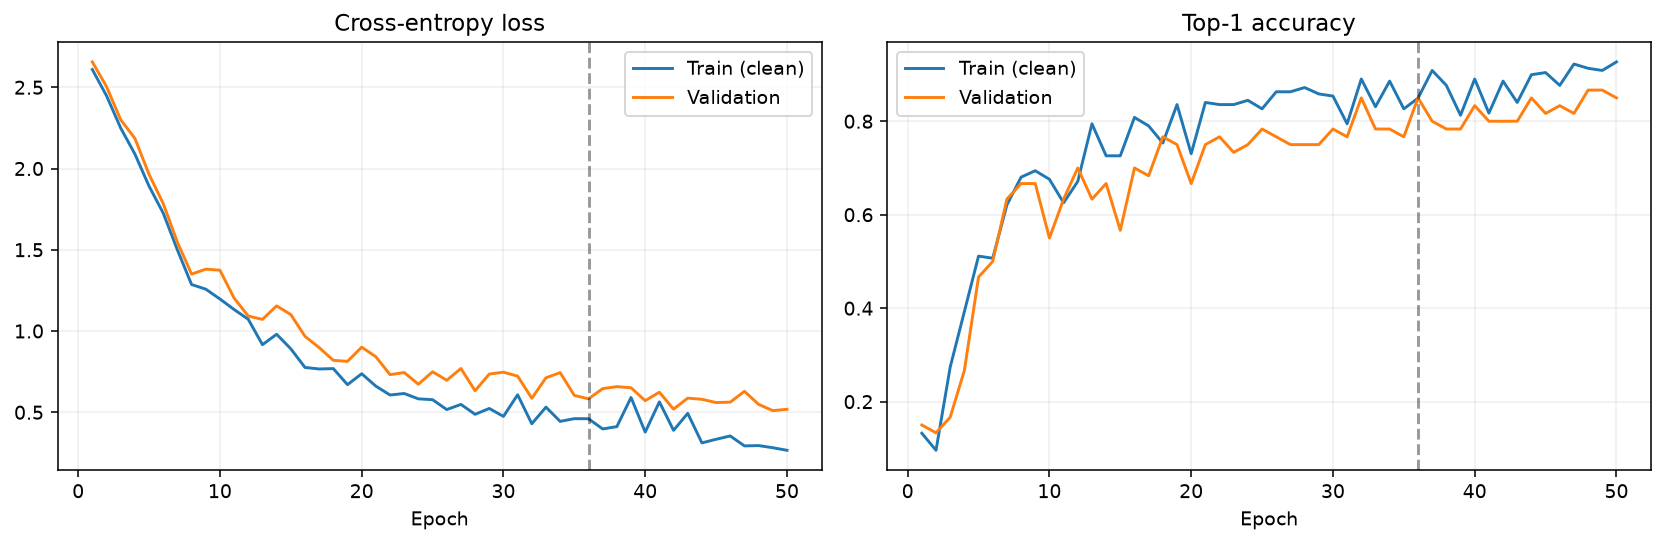

In [8]:
fig,axes=plt.subplots(1,2,figsize=(12,4));epochs=[r['epoch'] for r in history]
for k,label in [('train_clean','Train (clean)'),('val','Validation')]:
    axes[0].plot(epochs,[r[k]['loss'] for r in history],label=label);axes[1].plot(epochs,[r[k]['top1'] for r in history],label=label)
for ax,title in zip(axes,['Cross-entropy loss','Top-1 accuracy']):ax.axvline(chosen['epoch'],linestyle='--',color='black',alpha=.4);ax.set(title=title,xlabel='Epoch');ax.legend();ax.grid(alpha=.2)
plt.tight_layout();plt.show()
for label,values in results['test']['per_class'].items():print(label,values)

## Comparison with the earlier run

All 50 training epochs were completed; the validation-competitive small-gap rule selected backbone epoch 36, then a frozen linear readout was fitted. Epoch 50's **training-stage** classifier scored 92.69% on clean train and 85.00% on validation before readout fitting. Those figures are not the final fitted model's scores.

| Face-feature run | Epochs run | Selected backbone | Fitted validation | Fitted test | Test macro F1 |
|---|---:|---:|---:|---:|---:|
| Earlier | 17 | 17 | 53/60 | 141/182 | 78.00% |
| No early stopping | 50 | 36 | 50/60 | 151/182 | 83.07% |

The same 60 validation and 182 test clips were used and have been inspected in earlier development. This comparison used one random seed and does not establish a reliable generalization gain or webcam performance.
